In [65]:
import pandas as pd
import numpy as np
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    recall_score
)
import matplotlib.pyplot as plt

I have added all the imports to the above cell to make the notebook clearer, although they were first imported when required.

### Loading the dataset

In [66]:
data = pd.read_csv('datasets/legit-phish.csv')

### Preprocessing

In [67]:
data.isnull().sum()

URL                          0
url_length                   0
has_ip_address               0
dot_count                    0
https_flag                   0
url_entropy                  0
token_count                  0
subdomain_count              0
query_param_count            0
tld_length                   0
path_length                  0
has_hyphen_in_domain         0
number_of_digits             0
tld_popularity               0
suspicious_file_extension    0
domain_name_length           0
percentage_numeric_chars     0
ClassLabel                   1
dtype: int64

In [68]:
data[data['ClassLabel'].isnull()]

,URL,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars,ClassLabel
65118,https://www.chocolatleroux.com,30,0,2,1,3.898069,5,1,1,3,0,0,0,1,0,14,0.0,NaN


Since only one row contains a null value, we can delete it

In [69]:
data.dropna(subset=['ClassLabel'], inplace=True)

In [70]:
data.shape

(101218, 18)

In [71]:
data.head()


,URL,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars,ClassLabel
0,https://keraekken-loagginnusa.godaddysites.com/,47,0,2,1,4.250669,6,1,1,3,1,1,0,1,0,12,0.0,0.0
1,https://metamsk01lgiix.godaddysites.com/,40,0,2,1,4.196439,6,1,1,3,1,0,2,1,0,12,5.0,0.0
2,http://myglobaltech.in/,23,0,1,0,3.936180,5,0,1,2,1,0,0,0,0,12,0.0,0.0
3,http://djtool-for-spotify.com/,30,0,1,0,3.894740,5,0,1,3,1,1,0,1,0,18,0.0,0.0
4,https://scearmcoommunnlty.com/invent/freind/get,47,0,1,1,4.143127,7,0,1,3,18,0,0,1,0,17,0.0,0.0


Let's make the url_entropy values round to 3 integers.

In [72]:
data['url_entropy'] = data['url_entropy'].round(3)
data.head()

,URL,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars,ClassLabel
0,https://keraekken-loagginnusa.godaddysites.com/,47,0,2,1,4.251,6,1,1,3,1,1,0,1,0,12,0.0,0.0
1,https://metamsk01lgiix.godaddysites.com/,40,0,2,1,4.196,6,1,1,3,1,0,2,1,0,12,5.0,0.0
2,http://myglobaltech.in/,23,0,1,0,3.936,5,0,1,2,1,0,0,0,0,12,0.0,0.0
3,http://djtool-for-spotify.com/,30,0,1,0,3.895,5,0,1,3,1,1,0,1,0,18,0.0,0.0
4,https://scearmcoommunnlty.com/invent/freind/get,47,0,1,1,4.143,7,0,1,3,18,0,0,1,0,17,0.0,0.0


I think it will be nice to rename the target column into 'target'

In [73]:
data.rename(columns={'ClassLabel': 'target'}, inplace=True)
data.head()

,URL,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars,target
0,https://keraekken-loagginnusa.godaddysites.com/,47,0,2,1,4.251,6,1,1,3,1,1,0,1,0,12,0.0,0.0
1,https://metamsk01lgiix.godaddysites.com/,40,0,2,1,4.196,6,1,1,3,1,0,2,1,0,12,5.0,0.0
2,http://myglobaltech.in/,23,0,1,0,3.936,5,0,1,2,1,0,0,0,0,12,0.0,0.0
3,http://djtool-for-spotify.com/,30,0,1,0,3.895,5,0,1,3,1,1,0,1,0,18,0.0,0.0
4,https://scearmcoommunnlty.com/invent/freind/get,47,0,1,1,4.143,7,0,1,3,18,0,0,1,0,17,0.0,0.0


### About the dataset
Columns: 18 i.e 17 features and 1 target column

Rows: 101,219

Target column: target (1 = Legitimate, 0 = Phishing.)

### EDA

In [74]:
data['target'].value_counts()

target
0.0    63678
1.0    37540
Name: count, dtype: int64

In [75]:
data['target'].value_counts(normalize=True)

target
0.0    0.629117
1.0    0.370883
Name: proportion, dtype: float64

NOTE: There is an imbalance in the target class, so while splitting the data we need to make sure the ratio in the splits are also similar. The dataset consist of around 37% legitimate urls and the rest are phishing urls.

In [76]:
data.dtypes

URL                              str
url_length                     int64
has_ip_address                 int64
dot_count                      int64
https_flag                     int64
url_entropy                  float64
token_count                    int64
subdomain_count                int64
query_param_count              int64
tld_length                     int64
path_length                    int64
has_hyphen_in_domain           int64
number_of_digits               int64
tld_popularity                 int64
suspicious_file_extension      int64
domain_name_length             int64
percentage_numeric_chars     float64
target                       float64
dtype: object

In [77]:
data.nunique()

URL                          100872
url_length                      236
has_ip_address                    2
dot_count                        19
https_flag                        2
url_entropy                    1918
token_count                      32
subdomain_count                   7
query_param_count                 9
tld_length                       11
path_length                     198
has_hyphen_in_domain              2
number_of_digits                113
tld_popularity                    2
suspicious_file_extension         2
domain_name_length               36
percentage_numeric_chars       1479
target                            2
dtype: int64

In [78]:
data.describe().round()

,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars,target
count,101218.0,101218.0,101218.0,101218.0,101218.0,101218.0,101218.0,101218.0,101218.0,101218.0,101218.0,101218.0,101218.0,101218.0,101218.0,101218.0,101218.0
mean,35.0,0.0,3.0,0.0,4.0,7.0,2.0,1.0,5.0,9.0,0.0,9.0,0.0,0.0,6.0,24.0,0.0
std,17.0,0.0,1.0,0.0,0.0,2.0,1.0,0.0,3.0,15.0,0.0,9.0,0.0,0.0,5.0,22.0,0.0
min,7.0,0.0,0.0,0.0,3.0,1.0,-1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,27.0,0.0,2.0,0.0,4.0,5.0,1.0,1.0,3.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0
50%,31.0,0.0,3.0,0.0,4.0,7.0,2.0,1.0,3.0,2.0,0.0,10.0,0.0,0.0,3.0,20.0,0.0
75%,35.0,1.0,4.0,1.0,4.0,8.0,2.0,1.0,8.0,7.0,0.0,15.0,1.0,0.0,10.0,47.0,1.0
max,474.0,1.0,19.0,1.0,6.0,48.0,5.0,14.0,10.0,317.0,1.0,164.0,1.0,1.0,36.0,66.0,1.0


In [79]:
data['subdomain_count'].unique()

array([ 1,  0,  2,  5,  3, -1,  4])

subdomain_count = -1 is ambiguous, i am not sure if it is a unknown or it has some other significance, because it is not clearly mentioned on the dataset website also

In [80]:
data['subdomain_count'].value_counts()

subdomain_count
 2    55699
 1    41157
 0     2493
-1     1308
 3      502
 4       55
 5        4
Name: count, dtype: int64

In [81]:
data.loc[
    data["subdomain_count"] == -1,
    ["URL", "subdomain_count", "target"]
].head(20)

,URL,subdomain_count,target
599,Offline,-1,0.0
699,nobell.it/70ffb52d079109dca5664cce6f317373782/...,-1,0.0
700,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,-1,0.0
701,serviciosbys.com/paypal.cgi.bin.get-into.herf....,-1,0.0
702,mail.printakid.com/www.online.americanexpress....,-1,0.0
703,thewhiskeydregs.com/wp-content/themes/widescre...,-1,0.0
704,smilesvoegol.servebbs.org/voegol.php,-1,0.0
705,premierpaymentprocessing.com/includes/boleto-2...,-1,0.0
706,myxxxcollection.com/v1/js/jih321/bpd.com.do/do...,-1,0.0
707,super1000.info/docs,-1,0.0


In [82]:
data.groupby("subdomain_count")["target"].value_counts()

subdomain_count  target
-1               0.0        1308
 0               0.0        2309
                 1.0         184
 1               1.0       31873
                 0.0        9284
 2               0.0       50715
                 1.0        4984
 3               1.0         481
                 0.0          21
 4               0.0          37
                 1.0          18
 5               0.0           4
Name: count, dtype: int64

OMG, all the rows having -1 in subdomain_count are phishing urls. I thought of removing the rows with -1 in subdomain count, but i guess i will leave them for now and do an experiment on how to performance varies with and without them.

In [83]:
data['query_param_count'].unique()

array([ 1,  4,  2, 11,  3, 14,  6,  5, 12])

let's take all the columns with boolean values as 'categorical'. i know this is an oversimplification but I think this will be a good starting point

In [84]:
categorical = ['has_ip_address', 'https_flag', 'has_hyphen_in_domain', 'tld_popularity', 'suspicious_file_extension']

#### feature importance

let's calculate the feature importance for each of the categorical column

In [85]:
global_phish = 1 - data.target.mean()
global_phish

np.float64(0.6291173506688534)

In [86]:
%pip install ipython


[notice] A new release of pip is available: 26.1 -> 26.2.2
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [87]:
data['has_ip_address'].mean()

np.float64(0.4848841115216661)

In [88]:
for c in categorical:
    print(c)
    data_group = data.groupby(c).target.agg(['mean', 'count'])

    data_group['phishing_rate'] = 1 - data_group['mean']
    data_group['diff'] = data_group['phishing_rate'] - global_phish
    data_group['risk'] = data_group['phishing_rate'] / global_phish
    display(data_group)
    print()
    print()


has_ip_address


,mean,count,phishing_rate,diff,risk
has_ip_address,,,,,
0,0.719998,52139,0.280002,-0.349116,0.445070
1,0.000000,49079,1.000000,0.370883,1.589529




https_flag


,mean,count,phishing_rate,diff,risk
https_flag,,,,,
0,0.000083,60160,0.999917,0.370800,1.589396
1,0.914195,41058,0.085805,-0.543312,0.136390




has_hyphen_in_domain


,mean,count,phishing_rate,diff,risk
has_hyphen_in_domain,,,,,
0,0.358799,96876,0.641201,0.012084,1.019208
1,0.640488,4342,0.359512,-0.269606,0.571454




tld_popularity


,mean,count,phishing_rate,diff,risk
tld_popularity,,,,,
0,0.170731,67990,0.829269,0.200152,1.318147
1,0.780426,33228,0.219574,-0.409543,0.349019




suspicious_file_extension


,mean,count,phishing_rate,diff,risk
suspicious_file_extension,,,,,
0,0.434555,86378,0.565445,-0.063672,0.898791
1,0.000270,14840,0.999730,0.370613,1.589100


From the above output we have found some really interesting things. The most important finding is that 100% of the datapoints that have an IP address are phishing emails. Even the https_flag and suspicious_file_extension columns are good indicators

#### Feature importance: Mutual info score

In [89]:
from sklearn.metrics import mutual_info_score

In [90]:
def mutual_info_phish_score(series):
    return mutual_info_score(series, data.target)

In [91]:
mi = data[categorical].apply(mutual_info_phish_score)
mi.sort_values(ascending=False)

https_flag                   0.540170
has_ip_address               0.353983
tld_popularity               0.179622
suspicious_file_extension    0.074869
has_hyphen_in_domain         0.006682
dtype: float64

In [92]:
data.describe()

,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars,target
count,101218.000000,101218.000000,101218.000000,101218.000000,101218.000000,101218.000000,101218.000000,101218.000000,101218.000000,101218.000000,101218.000000,101218.000000,101218.000000,101218.000000,101218.000000,101218.000000,101218.000000
mean,35.061046,0.484884,3.007785,0.405639,3.976067,6.885752,1.511520,1.010591,5.003290,8.538333,0.042898,8.508753,0.328282,0.146614,6.292142,24.136725,0.370883
std,16.805753,0.499774,0.946612,0.491018,0.307092,1.670268,0.624756,0.202795,2.917436,14.701798,0.202627,8.540812,0.469590,0.353723,5.342686,22.490243,0.483043
min,7.000000,0.000000,0.000000,0.000000,2.522000,1.000000,-1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,0.000000,2.000000,0.000000,3.771000,5.000000,1.000000,1.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,31.000000,0.000000,3.000000,0.000000,3.937000,7.000000,2.000000,1.000000,3.000000,2.000000,0.000000,10.000000,0.000000,0.000000,3.000000,19.642857,0.000000
75%,35.000000,1.000000,4.000000,1.000000,4.101000,8.000000,2.000000,1.000000,8.000000,7.000000,0.000000,15.000000,1.000000,0.000000,10.000000,47.058824,1.000000
max,474.000000,1.000000,19.000000,1.000000,5.872000,48.000000,5.000000,14.000000,10.000000,317.000000,1.000000,164.000000,1.000000,1.000000,36.000000,65.957447,1.000000


### Feature Selection

The goal is to build an API that takes a URL as input and predicts whether it is legitimate or phishing. For this, I will use only features that can be calculated from the URL itself, without visiting the website.

**Features included**

The following features have clear definitions that we can implement directly:

- `url_length`
- `https_flag`
- `dot_count`
- `number_of_digits`
- `url_entropy`
- `path_length`
- `percentage_numeric_chars`

**Features included with our own defined rules**

These features can also be calculated from a URL, but we need to decide on consistent rules for calculating them:

- `has_ip_address`
- `subdomain_count`
- `query_param_count`
- `tld_length`
- `has_hyphen_in_domain`
- `domain_name_length`

**Features excluded initially**

I will leave these features out for now because their exact definitions or reference data are unclear:

- `token_count`
- `tld_popularity`
- `suspicious_file_extension`

I will recalculate the selected features from the original URL rather than relying on the dataset's precomputed values. This will ensure that the same feature-extraction logic can be used during both model training and API predictions.

#### NOTE: rather than using the features already present in the dataset we will recalculate these features so that they will be consistent to our final feature extraction in the final deployed version as the authors of the dataset did not provide how the features were extracted

In [93]:
included_features = [
    "url_length",
    "https_flag",
    "dot_count",
    "number_of_digits",
    "url_entropy",
    "path_length",
    "percentage_numeric_chars"
]

In [94]:
data = data.drop_duplicates(subset=["URL"], keep="first").reset_index(drop=True)

print("Dataset shape after removing duplicate URLs:", data.shape)
print("Remaining duplicate URLs:", data["URL"].duplicated().sum())

Dataset shape after removing duplicate URLs: (100872, 18)
Remaining duplicate URLs: 0


### Recalculating URL Features

In [95]:
from urllib.parse import urlsplit
from collections import Counter
import math

def extract_url_features(url):
    url = str(url)
    parsed_url = urlsplit(url)

    url_length = len(url)

    https_flag = int(parsed_url.scheme.lower() == "https")

    dot_count = url.count(".")

    number_of_digits = sum(char.isdigit() for char in url)

    if url:
        probabilities = [
            count / len(url)
            for count in Counter(url).values()
        ]
        url_entropy = -sum(
            p * math.log2(p) for p in probabilities
        )
    else:
        url_entropy = 0

    path_length = len(parsed_url.path)

    percentage_numeric_chars = (
        number_of_digits / url_length * 100
        if url_length else 0
    )

    return {
        "url_length": url_length,
        "https_flag": https_flag,
        "dot_count": dot_count,
        "number_of_digits": number_of_digits,
        "url_entropy": url_entropy,
        "path_length": path_length,
        "percentage_numeric_chars": percentage_numeric_chars,
    }

In [96]:
test_url = "https://example.com/login123"

features = extract_url_features(test_url)

print(features)

{'url_length': 28, 'https_flag': 1, 'dot_count': 1, 'number_of_digits': 3, 'url_entropy': 4.208966082694625, 'path_length': 9, 'percentage_numeric_chars': 10.714285714285714}


In [97]:
feature_data = pd.DataFrame(
    data['URL'].apply(extract_url_features).to_list(),
    index=data.index
)

feature_data['target'] = data['target'].astype(int)
display(feature_data.head())

,url_length,https_flag,dot_count,number_of_digits,url_entropy,path_length,percentage_numeric_chars,target
0,47,1,2,0,4.250669,1,0.0,0
1,40,1,2,2,4.196439,1,5.0,0
2,23,0,1,0,3.936180,1,0.0,0
3,30,0,1,0,3.894740,1,0.0,0
4,47,1,1,0,4.143127,18,0.0,0


In [98]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [99]:
data_full_train, data_test = train_test_split(
    feature_data,
    test_size=0.2,
    random_state=42,
    stratify=feature_data["target"]
)

data_train, data_val = train_test_split(
    data_full_train,
    test_size=0.25,
    random_state=42,
    stratify=data_full_train["target"]
)

# data_train = data_train.reset_index(drop=True)
# data_val = data_val.reset_index(drop=True)
# data_test = data_test.reset_index(drop=True)

y_train = data_train["target"]
y_val = data_val["target"]
y_test = data_test["target"]

X_train = data_train.drop(columns=["target"])
X_val = data_val.drop(columns=["target"])
X_test = data_test.drop(columns=["target"])

In [100]:
train_urls = set(data.loc[X_train.index, "URL"])
val_urls = set(data.loc[X_val.index, "URL"])
test_urls = set(data.loc[X_test.index, "URL"])

print("Train-validation overlap:", len(train_urls & val_urls))
print("Train-test overlap:", len(train_urls & test_urls))
print("Validation-test overlap:", len(val_urls & test_urls))

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0


### Training all baseline models and validating

#### Logistic Regression

In [101]:
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

logistic_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['url_length','https_flag','dot_count',...,'url_entropy','path_length', 'percentage_numeric_chars']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [102]:
y_pred = logistic_pipeline.predict(X_val)
y_pred_proba = logistic_pipeline.predict_proba(X_val)[:, 1]

print("Accuracy:", accuracy_score(y_val, y_pred))
print(classification_report(y_val,y_pred))
print("ROC AUC:", roc_auc_score(y_val, y_pred_proba))

Accuracy: 0.9883023543990087
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     12699
           1       0.98      0.99      0.98      7476

    accuracy                           0.99     20175
   macro avg       0.99      0.99      0.99     20175
weighted avg       0.99      0.99      0.99     20175

ROC AUC: 0.9989576746120437


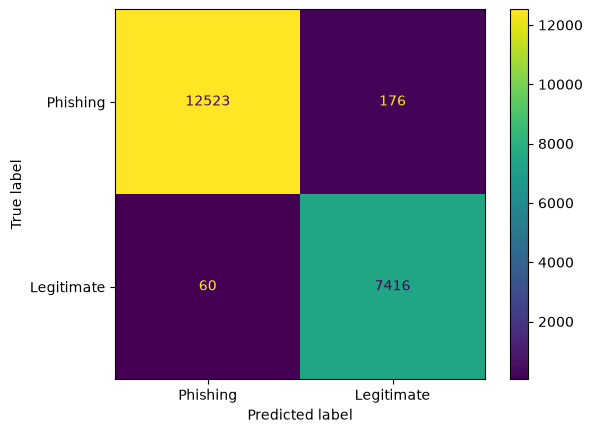

In [103]:
cm = confusion_matrix(y_val, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Phishing", "Legitimate"]
)

disp.plot()
plt.show()

lets make the validation process into a function

In [104]:
def evaluate_model(model, X_val=X_val, y_val=y_val, model_name="Model"):
    y_pred = model.predict(X_val)
    y_pred_proba = model.predict_proba(X_val)[:, 1]

    print(f"--- {model_name} ---")
    print(f"Accuracy: {accuracy_score(y_val, y_pred):.6f}")

    print("\nClassification Report:")
    print(classification_report(
        y_val,
        y_pred,
        target_names=["Phishing", "Legitimate"],
        digits=4,
        zero_division=0
    ))

    print(f"ROC AUC: {roc_auc_score(y_val, y_pred_proba):.6f}")

    phishing_recall = recall_score(y_val, y_pred, pos_label=0)
    cm = confusion_matrix(y_val, y_pred, labels=[0, 1])
    missed_phishing = cm[0, 1]

    print(f"Phishing Recall: {phishing_recall:.6f}")
    print(f"Missed phishing URLs: {missed_phishing}")

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Phishing", "Legitimate"]
    )

    disp.plot()
    plt.title(f"{model_name} - Confusion Matrix")
    plt.show()

--- Logistic Regression ---
Accuracy: 0.988302

Classification Report:
              precision    recall  f1-score   support

    Phishing     0.9952    0.9861    0.9907     12699
  Legitimate     0.9768    0.9920    0.9843      7476

    accuracy                         0.9883     20175
   macro avg     0.9860    0.9891    0.9875     20175
weighted avg     0.9884    0.9883    0.9883     20175

ROC AUC: 0.998958
Phishing Recall: 0.986141
Missed phishing URLs: 176


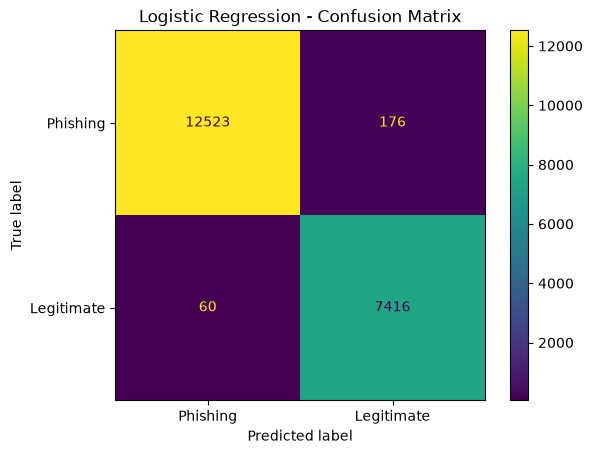

In [105]:
evaluate_model(logistic_pipeline, X_val, y_val, model_name="Logistic Regression")

#### KNN

In [106]:
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier()),
])

knn_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['url_length','https_flag','dot_count',...,'url_entropy','path_length', 'percentage_numeric_chars']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


--- KNN ---
Accuracy: 0.997224

Classification Report:
              precision    recall  f1-score   support

    Phishing     0.9978    0.9978    0.9978     12699
  Legitimate     0.9963    0.9963    0.9963      7476

    accuracy                         0.9972     20175
   macro avg     0.9970    0.9970    0.9970     20175
weighted avg     0.9972    0.9972    0.9972     20175

ROC AUC: 0.999067
Phishing Recall: 0.997795
Missed phishing URLs: 28


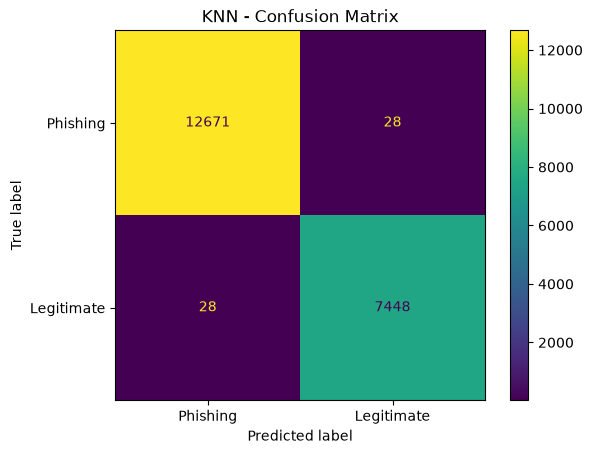

In [107]:
evaluate_model(model=knn_pipeline, model_name="KNN")

#### Decision Tree

--- Decision Tree ---
Accuracy: 0.997323

Classification Report:
              precision    recall  f1-score   support

    Phishing     0.9979    0.9979    0.9979     12699
  Legitimate     0.9964    0.9964    0.9964      7476

    accuracy                         0.9973     20175
   macro avg     0.9971    0.9971    0.9971     20175
weighted avg     0.9973    0.9973    0.9973     20175

ROC AUC: 0.997131
Phishing Recall: 0.997874
Missed phishing URLs: 27


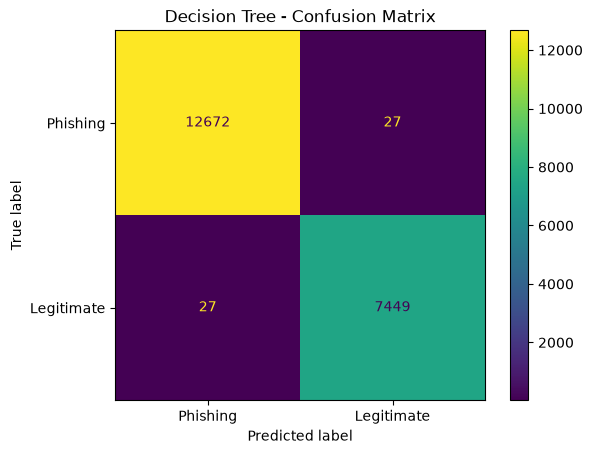

In [108]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

evaluate_model(model=dt, model_name="Decision Tree")

#### Random Forest

--- Random Forest ---
Accuracy: 0.998116

Classification Report:
              precision    recall  f1-score   support

    Phishing     0.9978    0.9992    0.9985     12699
  Legitimate     0.9987    0.9963    0.9975      7476

    accuracy                         0.9981     20175
   macro avg     0.9982    0.9977    0.9980     20175
weighted avg     0.9981    0.9981    0.9981     20175

ROC AUC: 0.999913
Phishing Recall: 0.999213
Missed phishing URLs: 10


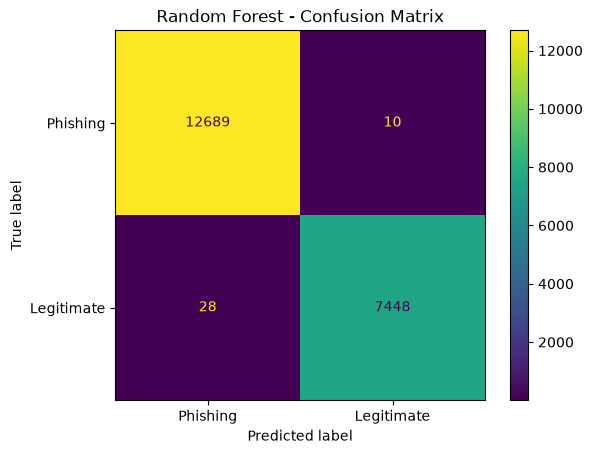

In [109]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)

rf.fit(X_train, y_train)

evaluate_model(model=rf, model_name="Random Forest")

#### XGBoost

--- XG Boost ---
Accuracy: 0.998216

Classification Report:
              precision    recall  f1-score   support

    Phishing     0.9981    0.9991    0.9986     12699
  Legitimate     0.9984    0.9968    0.9976      7476

    accuracy                         0.9982     20175
   macro avg     0.9983    0.9979    0.9981     20175
weighted avg     0.9982    0.9982    0.9982     20175

ROC AUC: 0.999961
Phishing Recall: 0.999055
Missed phishing URLs: 12


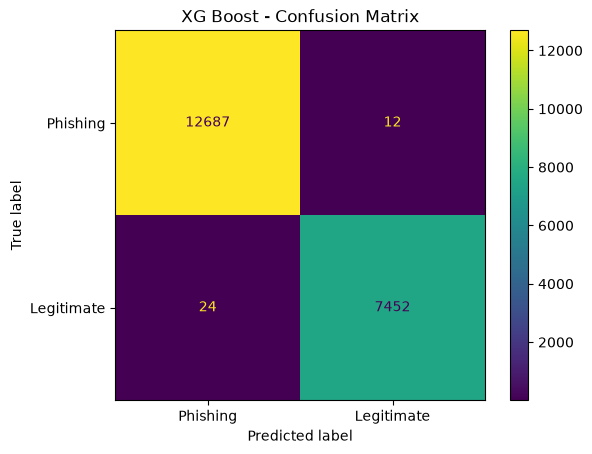

In [110]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators = 100,
    random_state = 42,
    eval_metric = "logloss",
    n_jobs= -1
)


xgb_model.fit(X_train, y_train)

evaluate_model(model=xgb_model, model_name="XG Boost")

Random Forest: Highest phishing recall, with only 10 missed phishing URLs

XGBoost: Highest accuracy and ROC-AUC, with 12 missed phishing URLs

So let's tune these two models

#### random forest tuning

In [111]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

In [112]:
rf_params = {
    "n_estimators": randint(100, 501),
    "max_depth": [None, 10, 20, 30, 40],
    "min_samples_split": randint(2, 11),
    "min_samples_leaf": randint(1, 5),
    "max_features": ["sqrt", "log2", None]
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=rf_params,
    n_iter=20,
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)
print("best parameters:", rf_search.best_params_)
print("best cv roc auc:", rf_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
best parameters: {'max_depth': 20, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 3, 'n_estimators': 443}
best cv roc auc: 0.9999693494252045


--- Tuned Random Forest ---
Accuracy: 0.998216

Classification Report:
              precision    recall  f1-score   support

    Phishing     0.9977    0.9994    0.9986     12699
  Legitimate     0.9991    0.9961    0.9976      7476

    accuracy                         0.9982     20175
   macro avg     0.9984    0.9978    0.9981     20175
weighted avg     0.9982    0.9982    0.9982     20175

ROC AUC: 0.999912
Phishing Recall: 0.999449
Missed phishing URLs: 7


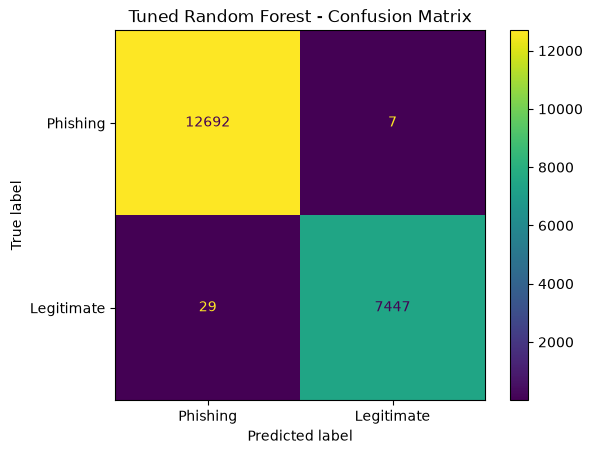

In [113]:
best_rf = rf_search.best_estimator_

evaluate_model(best_rf, model_name="Tuned Random Forest")

Slight improvement over the baseline RF

#### XGBoost tuning

In [114]:
xgb_model = XGBClassifier(
    n_estimators = 100,
    random_state = 42,
    eval_metric = "logloss",
    n_jobs= -1
)



xgb_params = {
    "n_estimators": randint(100, 501),
    "max_depth": randint(3, 11),
    "eta": [0.01, 0.03, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 0.9, 1.0],
}

xgb_search = RandomizedSearchCV(
    estimator=XGBClassifier(
        random_state=42,
        n_jobs=-1,
        eval_metric = "logloss",
    ),
    param_distributions=xgb_params,
    n_iter=20,
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train, y_train)
print("best parameters:", xgb_search.best_params_)
print("best cv roc auc:", xgb_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
best parameters: {'eta': 0.03, 'max_depth': 10, 'n_estimators': 487, 'subsample': 0.8}
best cv roc auc: 0.999968698069766


--- Tuned XG boost ---
Accuracy: 0.998216

Classification Report:
              precision    recall  f1-score   support

    Phishing     0.9983    0.9989    0.9986     12699
  Legitimate     0.9981    0.9971    0.9976      7476

    accuracy                         0.9982     20175
   macro avg     0.9982    0.9980    0.9981     20175
weighted avg     0.9982    0.9982    0.9982     20175

ROC AUC: 0.999963
Phishing Recall: 0.998898
Missed phishing URLs: 14


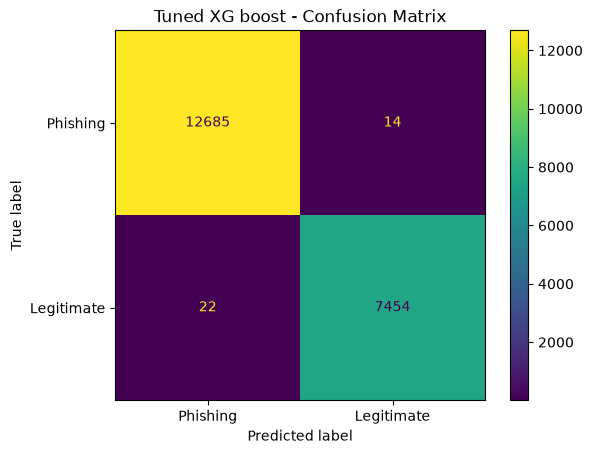

In [115]:
best_xgb = xgb_search.best_estimator_
evaluate_model(best_xgb, model_name="Tuned XG boost")

Although tuned Xgboost has higher roc, it fails to catch more phishing urls than random forest, for a phishing detectors a missed phishing url is more dangerous than a false positive (good url is flagged as phishing). So we will choose the tuned random forest model

#### Now let's train on the training and validation data combined

In [116]:
X_full_train = data_full_train.drop(columns=['target'])
y_full_train = data_full_train['target']

--- Final model ---
Accuracy: 0.998216

Classification Report:
              precision    recall  f1-score   support

    Phishing     0.9977    0.9994    0.9986     12699
  Legitimate     0.9991    0.9961    0.9976      7476

    accuracy                         0.9982     20175
   macro avg     0.9984    0.9978    0.9981     20175
weighted avg     0.9982    0.9982    0.9982     20175

ROC AUC: 0.999976
Phishing Recall: 0.999449
Missed phishing URLs: 7


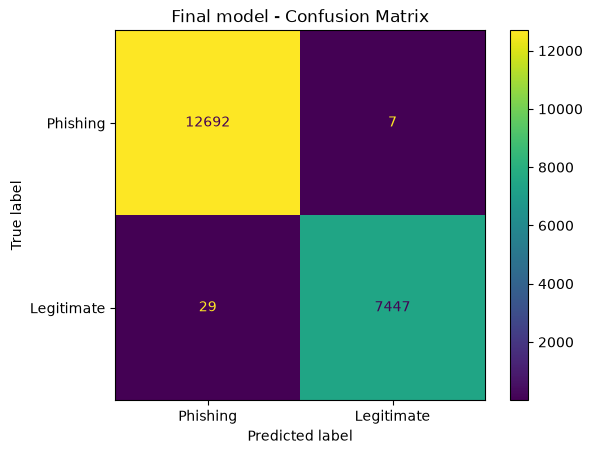

In [117]:
best_rf.fit(X_full_train, y_full_train)

evaluate_model(best_rf, X_test, y_test, model_name="Final model")

### saving the model

In [118]:
import joblib
joblib.dump(best_rf, "best_model.joblib")

['best_model.joblib']